In [ ]:
# path to the HS2 code, for imports
hs2_dir = 'C:\\Users\\Admin\\OneDrive\\Desktop\\UniBE\\src\\HS2\\'

from datetime import datetime
import sys, os

sys.path.append(hs2_dir)

# from herdingspikes.hs2 import HSDetection
# from herdingspikes.hs2 import HSClustering
# from herdingspikes.probe import BioCam

import matplotlib.pyplot as plt
import numpy as np
import pylab
import h5py
import json

In [ ]:
# PARAMETERS
##########################

# raw data file
data_file = "C:\\Users\\Admin\\OneDrive\\Desktop\\UniBE\\data\\150525_530_15_1a_DRC470_02.brw"
out_file = data_file.replace('.brw','')

# detection parameters
##########################

to_localize = True

# Spike cut-out size (values below are for 7kHz)
cutout_start = 4
cutout_end = 14
cutout_length = cutout_end+cutout_start+1

# detection threshold
threshold = 16


In [7]:
with h5py.File(data_file, 'r') as f:
    for key in f:
        print(f"Group: {key}")
        for subkey in f[key]:
            print(f"  Subgroup: {subkey}")

Group: ExperimentSettings
  Subgroup: b'{\r\n  "TimelineEvents": [],\r\n  "ValueConverter": {\r\n    "MinAnalogValue": -8000.0,\r\n    "MaxAnalogValue": 8000.0,\r\n    "MaxDigitalValue": 4095,\r\n    "MinDigitalValue": 0,\r\n    "ScaleFactor": 1.0,\r\n    "JsonVersion": 0\r\n  },\r\n  "TimeConverter": {\r\n    "FrameRate": 10103.0751953125\r\n  },\r\n  "ExperimentType": "Standard",\r\n  "ExperimentSettings": {\r\n    "Description": null,\r\n    "CalibrationCh": {\r\n      "Well": 1,\r\n      "Row": 1,\r\n      "Col": 1\r\n    },\r\n    "JsonVersion": 0\r\n  },\r\n  "SourceFilterSettings": {\r\n    "HighPassFilterCutOffFrequency": 100.0,\r\n    "HighPassFilterOrder": 2,\r\n    "JsonVersion": 0\r\n  },\r\n  "BiologicalModel": "Retina",\r\n  "TimelineIntervals": [],\r\n  "DataSettings": {\r\n    "Noise": {\r\n      "$type": "NoiseInfoDetectionSettings",\r\n      "DiscardOutliers": true,\r\n      "JsonVersion": 0\r\n    },\r\n    "Spikes": {\r\n      "$type": "SpikeDetectionSettings",\r\n 

In [4]:
with h5py.File(data_file, 'r') as f:
    sparse = f['Well_A1']['EventsBasedSparseRaw'][:]
    metadata = f['ExperimentSettings'][:]

json_str = metadata[0].decode('utf-8') # python dict serialized into byte format
my_dict = json.loads(json_str)
print(my_dict)
MaxVolt = my_dict['ValueConverter']['MaxAnalogValue']   # mV
MinVolt = my_dict['ValueConverter']['MinAnalogValue']  # mV
BitDepth = 16
SignalInversion = 1
MVOffset = SignalInversion * MinVolt   # Assume 0 unless otherwise specified

{'TimelineEvents': [], 'ValueConverter': {'MinAnalogValue': -8000.0, 'MaxAnalogValue': 8000.0, 'MaxDigitalValue': 4095, 'MinDigitalValue': 0, 'ScaleFactor': 1.0, 'JsonVersion': 0}, 'TimeConverter': {'FrameRate': 10103.0751953125}, 'ExperimentType': 'Standard', 'ExperimentSettings': {'Description': None, 'CalibrationCh': {'Well': 1, 'Row': 1, 'Col': 1}, 'JsonVersion': 0}, 'SourceFilterSettings': {'HighPassFilterCutOffFrequency': 100.0, 'HighPassFilterOrder': 2, 'JsonVersion': 0}, 'BiologicalModel': 'Retina', 'TimelineIntervals': [], 'DataSettings': {'Noise': {'$type': 'NoiseInfoDetectionSettings', 'DiscardOutliers': True, 'JsonVersion': 0}, 'EventsBasedRawRanges': {'$type': 'NoiseBlankingCompressionSettings', 'HigherPositiveStdFactor': 4.0, 'LowerPositiveStdFactor': 3.5, 'HigherNegativeStdFactor': 4.0, 'LowerNegativeStdFactor': 3.5, 'PreEventExtraSavedLengthMs': 0.0, 'PostEventExtraSavedLengthMs': 0.0, 'NeighborsScope': 'NoNeighbors', 'JsonVersion': 0}}, 'MeaSystem': {'HwVersion': {'Maj

In [5]:
print(len(sparse))

3096086286


In [ ]:
# Convert  sparse (digital) data to analog voltage
ADCCountsToMV = SignalInversion * ((MaxVolt - MinVolt) / (2 ** BitDepth))  # mV per count
ADCCountsTouV = ADCCountsToMV * 1000  # Convert mV to µV

# Convert digital data to µV
AnalogValue_uV = MVOffset + sparse * ADCCountsTouV
AnalogValue_uV

KeyboardInterrupt: 

In [6]:
Probe = BioCam(data_file, masked_channels=None)  # CHANGED KEY FROM RAW TO EventsBasedSparseRaw
H = HSDetection(Probe, to_localize, cutout_start, cutout_end, threshold,
                maa=0, maxsl=12, minsl=3, ahpthr=0, out_file_name=out_file, save_all=False)  # empty output file as input file is of wrong format

# 3Brain data format: BRW v4.x signal inversion 1.0
#       signal range:  -8000.0 -  8000.0
# Signal inversion looks like 1.0 , guessing the right method for data access.
# If your detection results look strange, signal polarity is wrong.



C:\Users\Admin\OneDrive\Desktop\UniBE\src\HS2\herdingspikes\hs2.py:154: UserWarning: cutout_start is deprecated and will be removed. Set left_cutout_time instead (in milliseconds). cutout_start takes priority over left_cutout_time!
  warnings.warn(msg.format(old_name, new_name, old_name, new_name))
C:\Users\Admin\OneDrive\Desktop\UniBE\src\HS2\herdingspikes\hs2.py:154: UserWarning: cutout_end is deprecated and will be removed. Set right_cutout_time instead (in milliseconds). cutout_end takes priority over right_cutout_time!
  warnings.warn(msg.format(old_name, new_name, old_name, new_name))
C:\Users\Admin\OneDrive\Desktop\UniBE\src\HS2\herdingspikes\hs2.py:154: UserWarning: minsl is deprecated and will be removed. Set amp_evaluation_time instead (in milliseconds). minsl takes priority over amp_evaluation_time!
  warnings.warn(msg.format(old_name, new_name, old_name, new_name))
C:\Users\Admin\OneDrive\Desktop\UniBE\src\HS2\herdingspikes\hs2.py:154: UserWarning: maxsl is deprecated and w

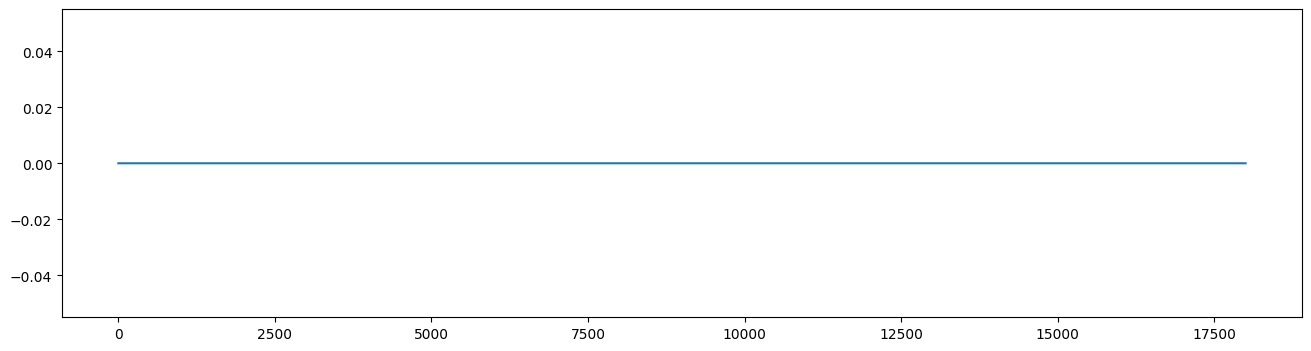

In [7]:
t1,t2 = 0,18000
data = Probe.Read(t1,t2).reshape(t2-t1,Probe.num_channels)
plt.figure(figsize=(16,4))
ch = 2786
plt.plot(data[:20000,ch])

In [8]:
# parameters:
#  tInc - number of frames to read in one batch (should not exceed available memory)
#  nFrames - number of frames to analyse, if not given, the whole recording will be analysed

H.DetectFromRaw(tInc=500000)

# Not Masking any Channels
# Sampling rate: 10103
# Localization On
# Number of recorded channels: 4096
# Analysing frames: 755880; Seconds: 74.81738097594774
# Frames before spike in cutout: 14
# Frames after spike in cutout: 16
# tcuts: 26 28
# tInc: 500000
# Detection completed, time taken: 0:00:38.028950
# Time per frame: 0:00:00.050311
# Time per sample: 0:00:00.000012
Loaded 0 spikes.


C:\Users\Admin\OneDrive\Desktop\UniBE\src\HS2\herdingspikes\hs2.py:186: UserWarning: Loading an empty file C:\Users\Admin\OneDrive\Desktop\UniBE\data\150525_530_15_1a_DRC470_02.bin . This usually happens when no spikes weredetected due to the detection parameters being set too strictly
  warnings.warn(


In [9]:
# read the detected spikes (opens a memmapped object)
H.LoadDetected()

Loaded 0 spikes.


(np.float64(-0.05500000000000001),
 np.float64(0.05500000000000001),
 np.float64(-0.05500000000000001),
 np.float64(0.05500000000000001))

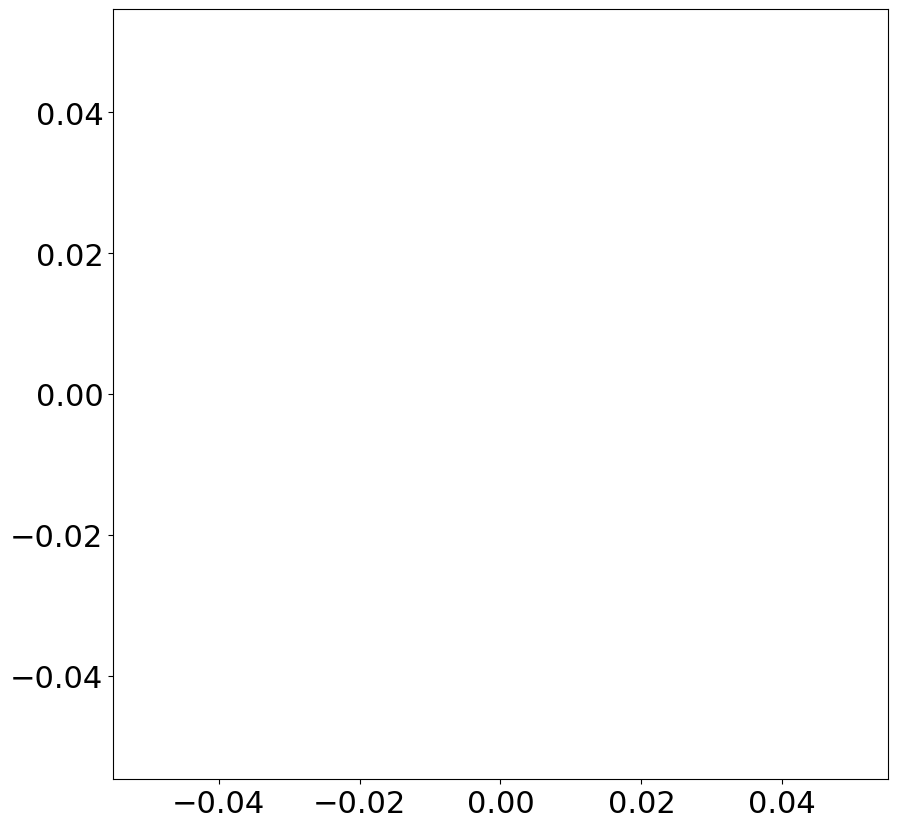

In [10]:
plt.figure(figsize=(10, 10))
ax = H.PlotAll(s=2,alpha=0.2,invert=True,c='k')
ax.tick_params(axis='x', labelsize=22)
ax.tick_params(axis='y', labelsize=22)
plt.axis('equal')